# 02 · EDA, quadratic OLS and fixed-effects regressions

Tests for an inverted-U relationship between the Federal Funds Rate and bank profitability (ROAQ, ROEQ, NIMQR). Input: `data/final_dataset.csv` from notebook 01.


In [33]:
# === 1) Imports ===
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import statsmodels.api as sm
from statsmodels.formula.api import ols
from statsmodels.stats.diagnostic import het_breuschpagan, linear_reset
from statsmodels.stats.stattools import durbin_watson
from linearmodels.panel import PanelOLS

# === 2) Notebook display ===
pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 120)
sns.set(context="notebook", style="whitegrid")


In [34]:
# === 3) Load cleaned dataset ===
DATA_PATH = "data/final_dataset.csv"
df = pd.read_csv(DATA_PATH)

print("Loaded:", DATA_PATH)
print("Shape:", df.shape)
df.head(3)

Loaded: data/final_dataset.csv
Shape: (639871, 12)


,CERT,QUARTER,ROAQ,ROEQ,NIMQR,FEDFUNDS,FEDFUNDS_CHANGE,equity_ratio,loan_ratio,deposit_ratio,funding_ratio,deposit_funding_ratio
0,10004,2023Q1,0.0051,0.0597,2.819395,4.52,0.87,9.350400,82.225829,82.981486,90.649600,0.915409
1,10011,2023Q1,0.0085,0.1686,3.160201,4.52,0.87,5.260864,67.435827,79.674906,94.739136,0.840993
2,10012,2023Q1,0.0023,0.0228,2.630143,4.52,0.87,10.329880,59.174107,86.055159,89.670120,0.959686


           ROAQ   ROEQ  NIMQR  FEDFUNDS
ROAQ      1.000  0.919  0.335     0.092
ROEQ      0.919  1.000  0.343     0.117
NIMQR     0.335  0.343  1.000     0.162
FEDFUNDS  0.092  0.117  0.162     1.000


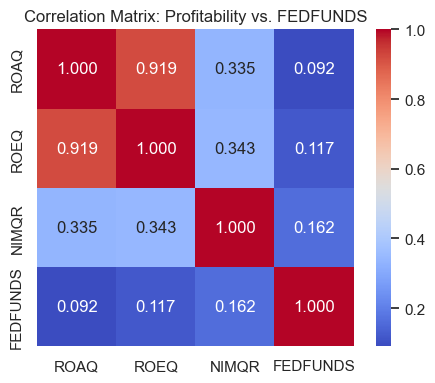

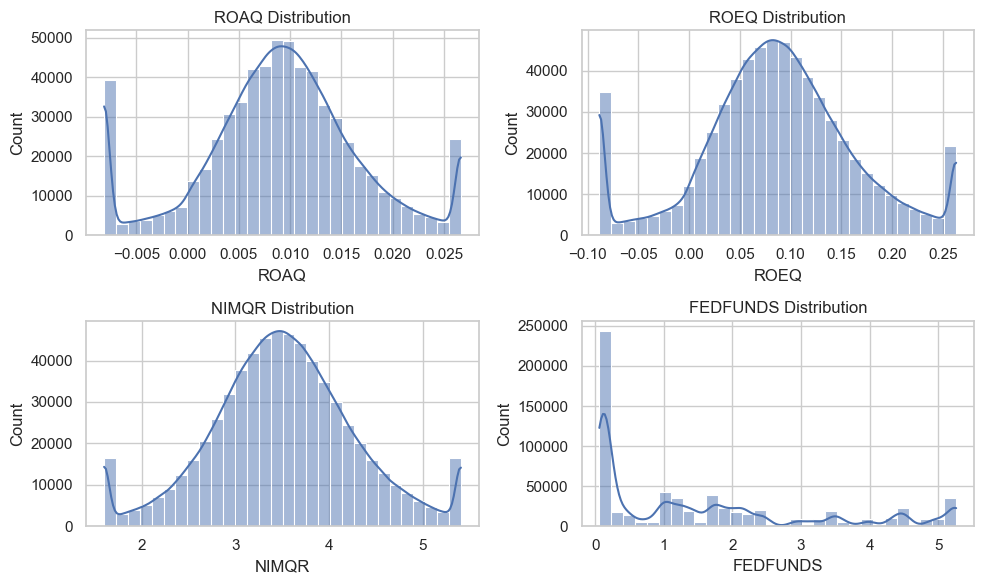

In [35]:
# === 4) Exploratory Data Analysis (EDA) ===

# --- Basic overview ---
df.describe().T.round(3)

# --- Correlation matrix for profitability + interest rate ---
corr_vars = ['ROAQ', 'ROEQ', 'NIMQR', 'FEDFUNDS']
corr = df[corr_vars].corr().round(3)
print(corr)

plt.figure(figsize=(5, 4))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.3f', square=True)
plt.title('Correlation Matrix: Profitability vs. FEDFUNDS')
plt.tight_layout()
plt.show()

# --- Quick distributions ---
fig, axes = plt.subplots(2, 2, figsize=(10, 6))
axes = axes.flatten()

for i, col in enumerate(['ROAQ', 'ROEQ', 'NIMQR', 'FEDFUNDS']):
    sns.histplot(df[col], bins=30, kde=True, ax=axes[i])
    axes[i].set_title(f'{col} Distribution')

plt.tight_layout()
plt.show()

In [36]:
# === 5) Descriptive Statistics for Key Variables ===

vars_summary = ['ROAQ', 'ROEQ', 'NIMQR', 'FEDFUNDS']

# --- Summary statistics ---
desc = df[vars_summary].describe().T.round(3)
desc['range'] = desc['max'] - desc['min']

# --- Display clean summary ---
desc[['mean', 'std', 'min', 'max', 'range']]

,mean,std,min,max,range
ROAQ,0.009,0.008,-0.008,0.027,0.035
ROEQ,0.086,0.078,-0.089,0.263,0.352
NIMQR,3.507,0.783,1.599,5.409,3.810
FEDFUNDS,1.549,1.646,0.060,5.260,5.200


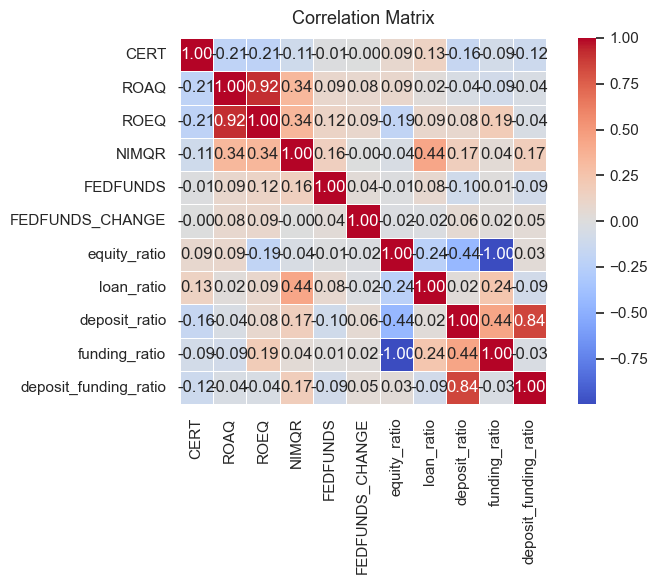

In [37]:
# === 6) Full correlation Matrix ===

plt.figure(figsize=(8, 6))
sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    square=True,
    linewidths=0.5
)

plt.title("Correlation Matrix", fontsize=13, pad=10)
plt.tight_layout()
plt.show()

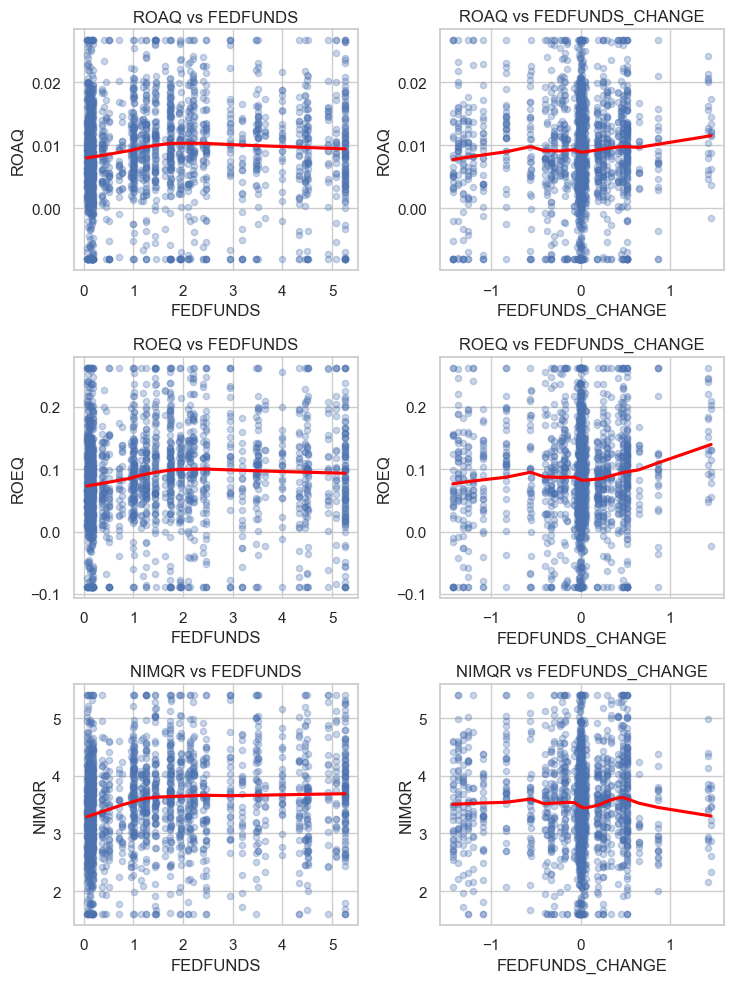

In [38]:
# === 7) Scatterplots: Profitability vs FEDFUNDS and FEDFUNDS_CHANGE ===

fig, axes = plt.subplots(3, 2, figsize=(7.5, 10))
targets = ['ROAQ', 'ROEQ', 'NIMQR']

for i, y in enumerate(targets):
    # --- FEDFUNDS level ---
    sns.regplot(
        x='FEDFUNDS', y=y, data=df.sample(2000, random_state=42),
        ax=axes[i, 0],
        scatter_kws={'alpha': 0.3, 's': 20},
        lowess=True,
        line_kws={'color': 'red'}
    )
    axes[i, 0].set_title(f'{y} vs FEDFUNDS')

    # --- FEDFUNDS change ---
    sns.regplot(
        x='FEDFUNDS_CHANGE', y=y, data=df.sample(2000, random_state=42),
        ax=axes[i, 1],
        scatter_kws={'alpha': 0.3, 's': 20},
        lowess=True,
        line_kws={'color': 'red'}
    )
    axes[i, 1].set_title(f'{y} vs FEDFUNDS_CHANGE')

plt.tight_layout()
plt.show()

In [39]:
# === 8) Baseline OLS Regressions (ROA, ROE, NIM vs FEDFUNDS) ===

targets = ['ROAQ', 'ROEQ', 'NIMQR']
results = {}

for y in targets:
    model = ols(f"{y} ~ FEDFUNDS", data=df).fit(cov_type='HC1')
    results[y] = model

    print(f"\n=== OLS: {y} on FEDFUNDS ===")
    print(model.summary().tables[1])


=== OLS: ROAQ on FEDFUNDS ===
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.0084   1.35e-05    620.590      0.000       0.008       0.008
FEDFUNDS       0.0004   6.05e-06     72.312      0.000       0.000       0.000

=== OLS: ROEQ on FEDFUNDS ===
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.0776      0.000    588.191      0.000       0.077       0.078
FEDFUNDS       0.0056   6.03e-05     92.244      0.000       0.005       0.006

=== OLS: NIMQR on FEDFUNDS ===
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      3.3871      0.001   2614.855      0.000       3.385       3.390
FEDFUNDS       0.0771      0.001    1

In [40]:
# === 9) Quadratic OLS Regressions (Testing for Inverted-U Relationship) ===

for y in targets:
    # --- Estimate quadratic model ---
    model_quad = ols(f"{y} ~ FEDFUNDS + I(FEDFUNDS**2)", data=df).fit(cov_type='HC1')
    results[y + '_quad'] = model_quad

    # --- Output summary ---
    print(f"\n=== Quadratic OLS: {y} ===")
    print(model_quad.summary().tables[1])

    # --- Compute turning point (peak profitability) ---
    b1 = model_quad.params['FEDFUNDS']
    b2 = model_quad.params['I(FEDFUNDS ** 2)']
    x_star = -b1 / (2 * b2)

    print(f"Peak profitability point for {y}: {x_star:.2f}% FEDFUNDS\n")


=== Quadratic OLS: ROAQ ===
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept            0.0078   1.65e-05    470.658      0.000       0.008       0.008
FEDFUNDS             0.0017   2.03e-05     83.985      0.000       0.002       0.002
I(FEDFUNDS ** 2)    -0.0003   4.09e-06    -65.104      0.000      -0.000      -0.000
Peak profitability point for ROAQ: 3.20% FEDFUNDS


=== Quadratic OLS: ROEQ ===
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept            0.0707      0.000    441.636      0.000       0.070       0.071
FEDFUNDS             0.0199      0.000     98.997      0.000       0.020       0.020
I(FEDFUNDS ** 2)    -0.0030   4.07e-05    -74.141      0.000      -0.003      -0.003
Peak profitability point for ROEQ: 3.30% 

In [41]:
# === 10) OLS Regressions with Clustered SEs (Δ FEDFUNDS Effect) ===

for y in targets:
    # --- Estimate model with clustered SEs (by bank) ---
    model_change = ols(f"{y} ~ FEDFUNDS_CHANGE", data=df).fit(
        cov_type='cluster',
        cov_kwds={'groups': df['CERT']}
    )

    # --- Output summary ---
    print(f"\n=== OLS (Clustered) {y} on FEDFUNDS_CHANGE ===")
    print(model_change.summary().tables[1])


=== OLS (Clustered) ROAQ on FEDFUNDS_CHANGE ===
                      coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept           0.0091   5.25e-05    173.739      0.000       0.009       0.009
FEDFUNDS_CHANGE     0.0013    2.8e-05     46.065      0.000       0.001       0.001

=== OLS (Clustered) ROEQ on FEDFUNDS_CHANGE ===
                      coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept           0.0868      0.001    170.088      0.000       0.086       0.088
FEDFUNDS_CHANGE     0.0150      0.000     53.296      0.000       0.014       0.016

=== OLS (Clustered) NIMQR on FEDFUNDS_CHANGE ===
                      coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept   

In [42]:
# === 11) Quadratic OLS (Clustered by Bank) ===

for y in targets:
    # --- Estimate model with bank-clustered SEs ---
    model_quad_cluster = ols(f"{y} ~ FEDFUNDS + I(FEDFUNDS**2)", data=df).fit(
        cov_type='cluster',
        cov_kwds={'groups': df['CERT']}
    )

    # --- Output summary ---
    print(f"\n=== Quadratic OLS (Clustered by Bank): {y} ===")
    print(model_quad_cluster.summary().tables[1])

    # --- Compute turning point (peak profitability) ---
    b1 = model_quad_cluster.params['FEDFUNDS']
    b2 = model_quad_cluster.params['I(FEDFUNDS ** 2)']
    x_star = -b1 / (2 * b2)

    print(f"Peak profitability point for {y}: {x_star:.2f}% FEDFUNDS\n")


=== Quadratic OLS (Clustered by Bank): ROAQ ===
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept            0.0078    6.5e-05    119.749      0.000       0.008       0.008
FEDFUNDS             0.0017   3.69e-05     46.220      0.000       0.002       0.002
I(FEDFUNDS ** 2)    -0.0003   6.41e-06    -41.616      0.000      -0.000      -0.000
Peak profitability point for ROAQ: 3.20% FEDFUNDS


=== Quadratic OLS (Clustered by Bank): ROEQ ===
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept            0.0707      0.001    115.760      0.000       0.070       0.072
FEDFUNDS             0.0199      0.000     53.345      0.000       0.019       0.021
I(FEDFUNDS ** 2)    -0.0030   6.48e-05    -46.567      0.000      -0.003      -0.003
P

In [43]:
# === 12) Quadratic OLS with Controls (Clustered by Bank) ===

controls = "equity_ratio + loan_ratio + deposit_ratio + funding_ratio + deposit_funding_ratio"

for y in targets:
    # --- Estimate model with controls and clustered SEs ---
    model_ctrl = ols(
        f"{y} ~ FEDFUNDS + I(FEDFUNDS**2) + {controls}",
        data=df
    ).fit(
        cov_type='cluster',
        cov_kwds={'groups': df['CERT']}
    )

    # --- Output summary ---
    print(f"\n=== Quadratic OLS with Controls (Clustered by Bank): {y} ===")
    print(model_ctrl.summary().tables[1])

    # --- Compute turning point (peak profitability) ---
    b1 = model_ctrl.params['FEDFUNDS']
    b2 = model_ctrl.params['I(FEDFUNDS ** 2)']
    x_star = -b1 / (2 * b2)

    print(f"Peak profitability (with controls) for {y}: {x_star:.2f}% FEDFUNDS\n")


=== Quadratic OLS with Controls (Clustered by Bank): ROAQ ===
                            coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------
Intercept                 1.1100      0.182      6.097      0.000       0.753       1.467
FEDFUNDS                  0.0018   3.73e-05     47.404      0.000       0.002       0.002
I(FEDFUNDS ** 2)         -0.0003   6.34e-06    -42.856      0.000      -0.000      -0.000
equity_ratio             -0.0101      0.002     -5.571      0.000      -0.014      -0.007
loan_ratio             1.551e-05   3.17e-06      4.892      0.000     9.3e-06    2.17e-05
deposit_ratio             0.0007    3.6e-05     19.863      0.000       0.001       0.001
funding_ratio            -0.0111      0.002     -6.105      0.000      -0.015      -0.008
deposit_funding_ratio    -0.0664      0.003    -19.521      0.000      -0.073      -0.060
Peak profitability (with controls) fo

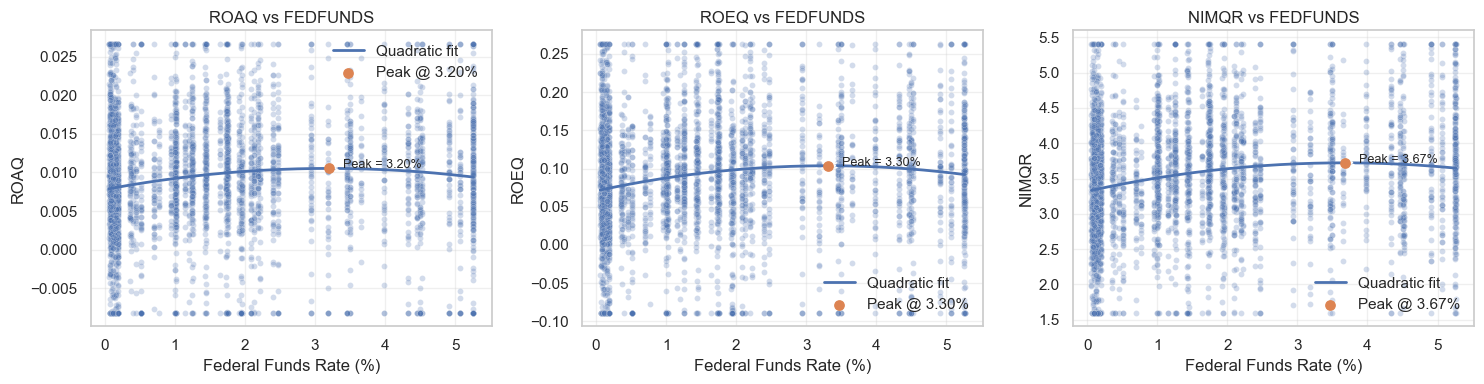

In [44]:
# === 13) Overlay Scatter + Predicted Quadratic Curve + Labeled Peak ===

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
targets = ['ROAQ', 'ROEQ', 'NIMQR']

# --- Sampling for readability ---
sample = df.sample(4000, random_state=42)
xgrid = np.linspace(df['FEDFUNDS'].min(), df['FEDFUNDS'].max(), 150)

for ax, y in zip(axes, targets):
    # --- Fit quadratic model with clustered SEs ---
    mod = ols(f"{y} ~ FEDFUNDS + I(FEDFUNDS**2)", data=df).fit(
        cov_type='cluster',
        cov_kwds={'groups': df['CERT']}
    )

    b0 = mod.params['Intercept']
    b1 = mod.params['FEDFUNDS']
    b2 = mod.params['I(FEDFUNDS ** 2)']

    # --- Predictions and turning point ---
    yhat = b0 + b1 * xgrid + b2 * (xgrid ** 2)
    x_star = -b1 / (2 * b2)
    y_star = b0 + b1 * x_star + b2 * (x_star ** 2)

    # --- Plot actual + predicted + peak ---
    sns.scatterplot(data=sample, x='FEDFUNDS', y=y, alpha=0.25, s=18, ax=ax)
    ax.plot(xgrid, yhat, lw=2, label='Quadratic fit')
    ax.scatter([x_star], [y_star], s=45, zorder=5, label=f'Peak @ {x_star:.2f}%')
    ax.annotate(
        f'Peak = {x_star:.2f}%',
        xy=(x_star, y_star),
        xytext=(x_star + 0.2, y_star),
        arrowprops=dict(arrowstyle='->', lw=1),
        fontsize=9
    )

    ax.set_title(f'{y} vs FEDFUNDS')
    ax.set_xlabel('Federal Funds Rate (%)')
    ax.set_ylabel(y)
    ax.legend(frameon=False)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [45]:
# === 14) Model Diagnostics: Heteroskedasticity, Autocorrelation, Specification ===

from statsmodels.stats.diagnostic import het_breuschpagan, linear_reset
from statsmodels.stats.stattools import durbin_watson

targets = ['ROAQ', 'ROEQ', 'NIMQR']

for y in targets:
    print(f"\n=== Diagnostics for {y} ===")

    # --- Fit quadratic OLS model ---
    model = ols(f"{y} ~ FEDFUNDS + I(FEDFUNDS**2)", data=df).fit()

    # --- Breusch–Pagan test for heteroskedasticity ---
    bp_pval = het_breuschpagan(model.resid, model.model.exog)[1]

    # --- Durbin–Watson test for autocorrelation ---
    dw_stat = durbin_watson(model.resid)

    # --- RESET test for model specification ---
    reset = linear_reset(model, power=2, test_type='fitted', use_f=True)
    reset_pval = reset.pvalue

    # --- Display results ---
    print(f"Breusch–Pagan p-value: {bp_pval:.4f}")
    print(f"Durbin–Watson statistic: {dw_stat:.3f}")
    print(f"RESET F-test: F={reset.fvalue:.2f}, p={reset_pval:.4e}")


=== Diagnostics for ROAQ ===
Breusch–Pagan p-value: 0.0000
Durbin–Watson statistic: 1.705
RESET F-test: F=247.83, p=7.9212e-56

=== Diagnostics for ROEQ ===
Breusch–Pagan p-value: 0.0000
Durbin–Watson statistic: 1.680
RESET F-test: F=297.06, p=1.4872e-66

=== Diagnostics for NIMQR ===
Breusch–Pagan p-value: 0.0000
Durbin–Watson statistic: 1.764
RESET F-test: F=1069.31, p=2.4175e-234


In [46]:
# === 15) Prepare Panel Data Structure for Fixed Effects Models ===

# --- Set multi-index (bank × quarter) ---
df_panel = df.set_index(['CERT', 'QUARTER'])

# --- Create squared term for FEDFUNDS ---
df_panel['FEDFUNDS_SQ'] = df_panel['FEDFUNDS'] ** 2

# --- Check index setup ---
df_panel.index.is_unique, df_panel.index.names

(True, FrozenList(['CERT', 'QUARTER']))

### Why the two-way (bank + time) fixed-effects results below should be ignored

FEDFUNDS is a single macro series: it takes the same value for every bank in a quarter. With quarter fixed effects it is perfectly collinear with the time dummies, so it is absorbed. The huge coefficients and ~0.99 p-values in the next two cells (and the `nan` peak with controls) are numerical noise, not estimates. They are kept to document the check. The specification that identifies the rate effect is **bank fixed effects without time effects** (section 18).


In [47]:
# === 16) Fixed Effects (Bank & Time) Panel Regressions ===

# --- Convert QUARTER (period) → quarter-end timestamp ---
df['QUARTER_TS'] = pd.PeriodIndex(df['QUARTER'], freq='Q').to_timestamp(how='end')

# --- Rebuild panel index and add squared term ---
df_panel = df.set_index(['CERT', 'QUARTER_TS']).copy()
df_panel['FEDFUNDS_SQ'] = df_panel['FEDFUNDS'] ** 2

# --- Run Fixed Effects (bank & time) models ---
from linearmodels.panel import PanelOLS

targets = ['ROAQ', 'ROEQ', 'NIMQR']

for y in targets:
    yv = df_panel[y]
    X = df_panel[['FEDFUNDS', 'FEDFUNDS_SQ']]

    mod = PanelOLS(yv, X, entity_effects=True, time_effects=True)
    res = mod.fit(cov_type='clustered', cluster_entity=True, cluster_time=True)

    # --- Compute turning point (if applicable) ---
    b1 = res.params.get('FEDFUNDS', np.nan)
    b2 = res.params.get('FEDFUNDS_SQ', np.nan)
    x_star = -b1 / (2 * b2) if pd.notna(b1) and pd.notna(b2) else np.nan

    # --- Display results ---
    print(f"\n=== FE (Bank & Time), Clustered — {y} ===")
    print(res.summary.tables[1])
    print(f"Peak profitability: {x_star:.2f}% FEDFUNDS")


=== FE (Bank & Time), Clustered — ROAQ ===
                              Parameter Estimates                              
             Parameter  Std. Err.     T-stat    P-value    Lower CI    Upper CI
-------------------------------------------------------------------------------
FEDFUNDS     1.495e+04  5.389e+06     0.0028     0.9978  -1.055e+07   1.058e+07
FEDFUNDS_SQ    -3234.3  1.044e+06    -0.0031     0.9975  -2.049e+06   2.043e+06
Peak profitability: 2.31% FEDFUNDS

=== FE (Bank & Time), Clustered — ROEQ ===
                              Parameter Estimates                              
             Parameter  Std. Err.     T-stat    P-value    Lower CI    Upper CI
-------------------------------------------------------------------------------
FEDFUNDS     2.472e+05  5.809e+07     0.0043     0.9966  -1.136e+08   1.141e+08
FEDFUNDS_SQ -5.299e+04  1.133e+07    -0.0047     0.9963  -2.226e+07   2.215e+07
Peak profitability: 2.33% FEDFUNDS

=== FE (Bank & Time), Clustered — NIMQR =

In [48]:
# === 17) Fixed Effects (Bank & Time) with Controls, Clustered SEs ===

controls = ['equity_ratio', 'loan_ratio', 'deposit_ratio', 'funding_ratio', 'deposit_funding_ratio']
targets  = ['ROAQ', 'ROEQ', 'NIMQR']

for y in targets:
    yv = df_panel[y]
    X  = df_panel[['FEDFUNDS', 'FEDFUNDS_SQ'] + controls]

    mod = PanelOLS(yv, X, entity_effects=True, time_effects=True, drop_absorbed=True)
    res = mod.fit(cov_type='clustered', cluster_entity=True, cluster_time=True)

    # Turning point only if rate terms survive absorption
    b1 = res.params.get('FEDFUNDS', np.nan)
    b2 = res.params.get('FEDFUNDS_SQ', np.nan)
    x_star = (-b1 / (2 * b2)) if (pd.notna(b1) and pd.notna(b2)) else np.nan

    print(f"\n=== FE (Bank & Time) with Controls — {y} ===")
    print(res.summary.tables[1])
    print(f"Peak profitability (FE + controls): {x_star:.2f}% FEDFUNDS")

<ipykernel cell>:11: AbsorbingEffectWarning: 
Variables have been fully absorbed and have removed from the regression:

FEDFUNDS, FEDFUNDS_SQ

  res = mod.fit(cov_type='clustered', cluster_entity=True, cluster_time=True)



=== FE (Bank & Time) with Controls — ROAQ ===
                                   Parameter Estimates                                   
                       Parameter  Std. Err.     T-stat    P-value    Lower CI    Upper CI
-----------------------------------------------------------------------------------------
equity_ratio             -0.0102     0.0028    -3.6806     0.0002     -0.0156     -0.0048
loan_ratio                0.0001    4.2e-06     25.788     0.0000      0.0001      0.0001
deposit_ratio             0.0004  2.454e-05     15.825     0.0000      0.0003      0.0004
funding_ratio            -0.0107     0.0028    -3.8804     0.0001     -0.0162     -0.0053
deposit_funding_ratio    -0.0364     0.0021    -17.007     0.0000     -0.0406     -0.0322
Peak profitability (FE + controls): nan% FEDFUNDS


<ipykernel cell>:11: AbsorbingEffectWarning: 
Variables have been fully absorbed and have removed from the regression:

FEDFUNDS, FEDFUNDS_SQ

  res = mod.fit(cov_type='clustered', cluster_entity=True, cluster_time=True)



=== FE (Bank & Time) with Controls — ROEQ ===
                                   Parameter Estimates                                   
                       Parameter  Std. Err.     T-stat    P-value    Lower CI    Upper CI
-----------------------------------------------------------------------------------------
equity_ratio             -0.0934     0.0312    -2.9951     0.0027     -0.1545     -0.0323
loan_ratio                0.0010  4.667e-05     21.163     0.0000      0.0009      0.0011
deposit_ratio             0.0023     0.0002     11.868     0.0000      0.0019      0.0027
funding_ratio            -0.0918     0.0312    -2.9410     0.0033     -0.1530     -0.0306
deposit_funding_ratio    -0.2332     0.0164    -14.260     0.0000     -0.2652     -0.2011
Peak profitability (FE + controls): nan% FEDFUNDS


<ipykernel cell>:11: AbsorbingEffectWarning: 
Variables have been fully absorbed and have removed from the regression:

FEDFUNDS, FEDFUNDS_SQ

  res = mod.fit(cov_type='clustered', cluster_entity=True, cluster_time=True)



=== FE (Bank & Time) with Controls — NIMQR ===
                                   Parameter Estimates                                   
                       Parameter  Std. Err.     T-stat    P-value    Lower CI    Upper CI
-----------------------------------------------------------------------------------------
equity_ratio             -0.2318     0.1733    -1.3375     0.1811     -0.5715      0.1079
loan_ratio                0.0259     0.0005     49.443     0.0000      0.0248      0.0269
deposit_ratio             0.0061     0.0029     2.0780     0.0377      0.0003      0.0118
funding_ratio            -0.2795     0.1733    -1.6123     0.1069     -0.6192      0.0603
deposit_funding_ratio     0.5675     0.2881     1.9700     0.0488      0.0029      1.1322
Peak profitability (FE + controls): nan% FEDFUNDS


In [49]:
# === 18) Fixed Effects (Bank only) Quadratic Model ===

from linearmodels.panel import PanelOLS

targets = ['ROAQ', 'ROEQ', 'NIMQR']

for y in targets:
    yv = df_panel[y]
    X = df_panel[['FEDFUNDS', 'FEDFUNDS_SQ'] + controls]

    mod = PanelOLS(yv, X, entity_effects=True, drop_absorbed=True)
    res = mod.fit(cov_type='clustered', cluster_entity=True)

    b1 = res.params.get('FEDFUNDS', np.nan)
    b2 = res.params.get('FEDFUNDS_SQ', np.nan)
    x_star = (-b1 / (2 * b2)) if pd.notna(b1) and pd.notna(b2) else np.nan

    print(f"\n=== Bank Fixed Effects Only — {y} ===")
    print(res.summary.tables[1])
    print(f"Peak profitability (Bank FE): {x_star:.2f}% FEDFUNDS")


=== Bank Fixed Effects Only — ROAQ ===
                                   Parameter Estimates                                   
                       Parameter  Std. Err.     T-stat    P-value    Lower CI    Upper CI
-----------------------------------------------------------------------------------------
FEDFUNDS                  0.0015  3.387e-05     45.350     0.0000      0.0015      0.0016
FEDFUNDS_SQ              -0.0002   5.71e-06    -38.707     0.0000     -0.0002     -0.0002
equity_ratio             -0.0106     0.0025    -4.1685     0.0000     -0.0155     -0.0056
loan_ratio             8.521e-05  2.984e-06     28.558     0.0000   7.936e-05   9.106e-05
deposit_ratio             0.0004  1.874e-05     23.100     0.0000      0.0004      0.0005
funding_ratio            -0.0112     0.0025    -4.4011     0.0000     -0.0161     -0.0062
deposit_funding_ratio    -0.0355     0.0018    -19.730     0.0000     -0.0391     -0.0320
Peak profitability (Bank FE): 3.48% FEDFUNDS

=== Bank Fixed

<ipykernel cell>:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


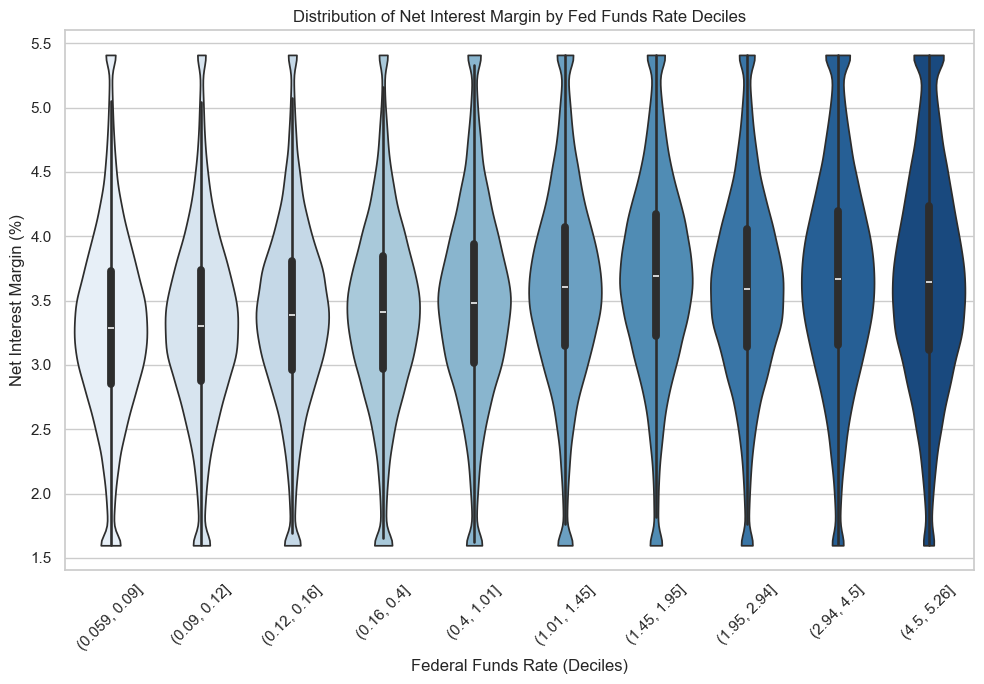

In [50]:
# === 19) Violin plots ===


import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# create bins by rate level
df['rate_bin'] = pd.qcut(df['FEDFUNDS'], q=10, duplicates='drop')

plt.figure(figsize=(10,7))
sns.violinplot(
    x='rate_bin', y='NIMQR', data=df,
    inner='box', palette='Blues', cut=0
)
plt.xticks(rotation=45)
plt.title('Distribution of Net Interest Margin by Fed Funds Rate Deciles')
plt.xlabel('Federal Funds Rate (Deciles)')
plt.ylabel('Net Interest Margin (%)')
plt.tight_layout()
plt.show()

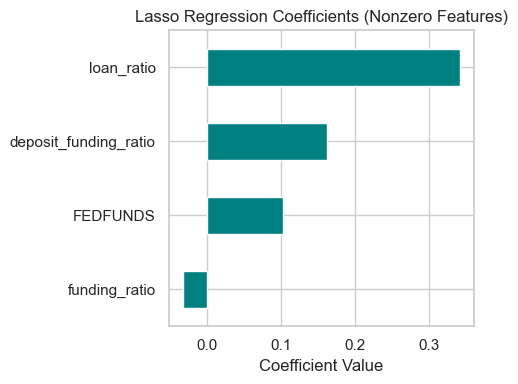

Selected features: ['funding_ratio', 'FEDFUNDS', 'deposit_funding_ratio', 'loan_ratio']


In [ ]:
# === Lasso Regression for Robustness Check ===
from sklearn.linear_model import LassoCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
import matplotlib.pyplot as plt
import pandas as pd

# Create squared term if it doesn't exist
if 'FEDFUNDS_SQ' not in df.columns:
    df['FEDFUNDS_SQ'] = df['FEDFUNDS'] ** 2

# Prepare features and target
features = [
    'FEDFUNDS', 'FEDFUNDS_SQ', 'equity_ratio', 'loan_ratio',
    'deposit_ratio', 'funding_ratio', 'deposit_funding_ratio'
]
X = df[features].dropna()
y = df.loc[X.index, 'NIMQR']

# Build and fit Lasso with cross-validation
lasso = make_pipeline(StandardScaler(), LassoCV(cv=5, random_state=42))
lasso.fit(X, y)

# Extract nonzero coefficients
coefs = pd.Series(lasso.named_steps['lassocv'].coef_, index=X.columns)
coefs = coefs[coefs != 0].sort_values(key=abs, ascending=True)

# Plot
plt.figure(figsize=(5,4))
coefs.plot(kind='barh', color='teal')
plt.title('Lasso Regression Coefficients (Nonzero Features)')
plt.xlabel('Coefficient Value')
plt.tight_layout()
plt.show()

print("Selected features:", list(coefs.index))